# Implementing Image Classification through Fourier Neural Operator


## Backend : JAX
## Datasets : MNIST IDX files

### GPU : GB10 (DGX-Spark)

In this notebook we will introduce the brief theory behind the Fourier Neural Operators and use them to solve a data-driven image classification problem. The theory is adopted from the [paper](https://arxiv.org/pdf/2010.08895.pdf) by Zongyi Li et al.

This notebook follows the same flow as the Tensorflow / Keras version, but the model and training loop are rewritten in JAX to avoid the current TensorFlow cuFFT issue on GB10.

---
## Import Necessary Libraries

In [2]:
# Install once in your container if needed:
# !python -m pip install -U "jax[cuda12]" numpy

# Import Necessary Libraries : JAX and helper APIs
from __future__ import annotations

import gzip
import struct
import time
import urllib.request
from pathlib import Path
from typing import Any

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

# Only used in Jupyter notebook
%matplotlib inline


print("JAX devices:", jax.devices())

JAX devices: [CudaDevice(id=0)]


---
##  Comfirming the GPU configuration

The JAX APIs about testing whether the GPU is functioning are as follow :

- **The Python Code**

```python
  import jax
  print(jax.devices())
```

- **output**

If the GB10 GPU is available, the device list should include a CUDA/GPU device instead of CPU only.

In [3]:
devices = jax.devices()
print('JAX devices:', devices)

if any(device.platform == 'gpu' for device in devices):
    print('Default GPU Device:{}'.format(jax.default_backend()))
else:
    print('Please install GPU version of JAX')

JAX devices: [CudaDevice(id=0)]
Default GPU Device:gpu


---
## Preparing Datasets

Since this notebook avoids TensorFlow completely, MNIST is downloaded from the public IDX files and parsed directly with Python / NumPy.

In [4]:
MNIST_URLS = {
    "train_images": "https://storage.googleapis.com/cvdf-datasets/mnist/train-images-idx3-ubyte.gz",
    "train_labels": "https://storage.googleapis.com/cvdf-datasets/mnist/train-labels-idx1-ubyte.gz",
    "test_images": "https://storage.googleapis.com/cvdf-datasets/mnist/t10k-images-idx3-ubyte.gz",
    "test_labels": "https://storage.googleapis.com/cvdf-datasets/mnist/t10k-labels-idx1-ubyte.gz",
}


def download_file(url: str, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        return
    print(f"Downloading {url} -> {path}")
    urllib.request.urlretrieve(url, path)


def read_idx_images(path: Path) -> np.ndarray:
    with gzip.open(path, "rb") as f:
        magic, count, rows, cols = struct.unpack(">IIII", f.read(16))
        if magic != 2051:
            raise ValueError(f"Unexpected image file magic {magic} in {path}")
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.reshape(count, rows, cols, 1).astype(np.float32) / 255.0


def read_idx_labels(path: Path) -> np.ndarray:
    with gzip.open(path, "rb") as f:
        magic, count = struct.unpack(">II", f.read(8))
        if magic != 2049:
            raise ValueError(f"Unexpected label file magic {magic} in {path}")
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels.astype(np.int32).reshape(count)


def load_mnist(data_dir: Path) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    files = {name: data_dir / Path(url).name for name, url in MNIST_URLS.items()}
    for name, url in MNIST_URLS.items():
        download_file(url, files[name])

    train_images = read_idx_images(files["train_images"])
    train_labels = read_idx_labels(files["train_labels"])
    test_images = read_idx_images(files["test_images"])
    test_labels = read_idx_labels(files["test_labels"])
    return train_images, train_labels, test_images, test_labels

---
# Applying Fourier Neural Operator

## FNO Theory

Fourier neural operator (FNO) is a data-driven architecture which can be used to parameterize solutions for a distribution of PDE solutions. The key feature of FNO is the spectral convolutions: operations that place the integral kernel in Fourier space. The spectral convolution (Fourier integral operator) is defined as follows:

\begin{equation}
(\mathcal{K}(\mathbf{w})\phi)(x) = \mathcal{F}^{-1}(R_{\mathbf{W}}\cdot \left(\mathcal{F}\right)\phi)(x), \quad \forall x \in D
\end{equation}

where $\mathcal{F}$ and $\mathcal{F}^{-1}$ are the forward and inverse Fourier transforms, respectively. $R_{\mathbf{w}}$ is the transformation which contains the learnable parameters $\mathbf{w}$.

Fast Fourier Transform (FFT) is used to perform the Fourier transforms efficiently and the resulting transformation $R_{\mathbf{w}}$ is a finite size matrix of learnable weights. Inside the spectral convolution, the Fourier coefficients are truncated to only the lower modes, which allows explicit control over the dimensionality of the spectral space and linear operator.

In this JAX version, the same FNO idea is implemented with `jnp.fft.rfft2` and `jnp.fft.irfft2`.

---
## Fourier Neural Operator (FNO) Control Flow

![FNO Model Control Flow](FNO_Model_CF.png)

---

***First Part***

The first step we should implement is raising the dimension through a point-wise linear layer, which plays the same role as the original 1 x 1 convolution encoder layer.

$$a(x) \rightarrow P $$

---------------

***Middle Part***

As we get the higher dimensional input space, we start to build our Fourier Neural Operator.

This method divides the input into two parts. One enters Fourier space through fast Fourier transform, and the other path is kept as a residual to supplement the signal after spectral truncation and linear transform.

After finishing the steps above, we add the two paths together and connect them with ReLU activation.

We repeat the steps four times and then output the result to the final part.

--------

***Final Part***

After we obtain the output from FNO, we decode the latent output through point-wise decoder layers and dense classifier layers, then output our final class probabilities.

$$Q  \rightarrow u(x) $$

---
# Defining the Model Components

The original notebook used Keras layers (`P`, `FourierLayer`, and `Q`). In JAX, we define the same parts as parameter dictionaries and pure functions.

In [5]:
# First Part : Defining a(x) --> P
# Final Part : Defining Q --> u(x)
#
# In JAX, trainable layers are stored explicitly as parameter dictionaries.

def glorot(key: jax.Array, shape: tuple[int, ...]) -> jax.Array:
    fan_in = np.prod(shape[:-1]) if len(shape) > 1 else shape[0]
    fan_out = shape[-1]
    limit = np.sqrt(6.0 / (fan_in + fan_out))
    return jax.random.uniform(key, shape, minval=-limit, maxval=limit, dtype=jnp.float32)


def init_dense(key: jax.Array, in_dim: int, out_dim: int) -> dict[str, jax.Array]:
    return {
        "w": glorot(key, (in_dim, out_dim)),
        "b": jnp.zeros((out_dim,), dtype=jnp.float32),
    }


def init_spectral_layer(
    key: jax.Array,
    channels: int,
    modes1: int,
    modes2: int,
) -> dict[str, jax.Array]:
    keys = jax.random.split(key, 4)
    scale = 1.0 / max(1, channels * channels)
    shape = (channels, channels, modes1, modes2)
    return {
        "w1_re": jax.random.uniform(keys[0], shape, minval=-scale, maxval=scale),
        "w1_im": jax.random.uniform(keys[1], shape, minval=-scale, maxval=scale),
        "w2_re": jax.random.uniform(keys[2], shape, minval=-scale, maxval=scale),
        "w2_im": jax.random.uniform(keys[3], shape, minval=-scale, maxval=scale),
    }


def init_params(
    seed: int,
    width: int = 64,
    modes1: int = 4,
    modes2: int = 4,
    num_spectral_layers: int = 4,
) -> dict[str, Any]:
    keys = jax.random.split(jax.random.PRNGKey(seed), 4 + num_spectral_layers)
    return {
        "lift": {
            "w": glorot(keys[0], (1, width)),
            "b": jnp.zeros((width,), dtype=jnp.float32),
        },
        "spectral": [
            init_spectral_layer(keys[i + 1], width, modes1, modes2)
            for i in range(num_spectral_layers)
        ],
        "q": init_dense(keys[-3], width, width),
        "dense1": init_dense(keys[-2], 16 * 16 * width, 784),
        "dense2": init_dense(keys[-1], 784, 10),
    }

---
# Building the Model of Fourier Neural Operator (FNO)

The forward pass follows the original notebook:

- Zero-pad MNIST images from `28 x 28` to `32 x 32`.
- Lift the channel dimension to `WIDTH = 64`.
- Downsample to `16 x 16`.
- Apply four Fourier layers.
- Decode and classify into 10 MNIST classes.

In [6]:
# Middle Part : Defining FFT and residual block

def max_pool_2x2(x: jax.Array) -> jax.Array:
    batch, height, width, channels = x.shape
    x = x.reshape(batch, height // 2, 2, width // 2, 2, channels)
    return x.max(axis=(2, 4))


def pointwise(x: jax.Array, params: dict[str, jax.Array]) -> jax.Array:
    return jnp.einsum("bhwc,co->bhwo", x, params["w"]) + params["b"]


def spectral_conv2d(x: jax.Array, params: dict[str, jax.Array]) -> jax.Array:
    # JAX FFTs operate on the requested axes, so we use NCHW to match FNO notation.
    x = jnp.transpose(x, (0, 3, 1, 2))
    batch, channels, height, width = x.shape
    modes1 = params["w1_re"].shape[-2]
    modes2 = params["w1_re"].shape[-1]
    width_ft = width // 2 + 1

    x_ft = jnp.fft.rfft2(x, axes=(-2, -1))
    out_ft = jnp.zeros((batch, channels, height, width_ft), dtype=jnp.complex64)

    weights1 = params["w1_re"] + 1j * params["w1_im"]
    weights2 = params["w2_re"] + 1j * params["w2_im"]

    out_first = jnp.einsum("bcxy,coxy->boxy", x_ft[:, :, :modes1, :modes2], weights1)
    out_end = jnp.einsum("bcxy,coxy->boxy", x_ft[:, :, -modes1:, :modes2], weights2)

    out_ft = out_ft.at[:, :, :modes1, :modes2].set(out_first)
    out_ft = out_ft.at[:, :, -modes1:, :modes2].set(out_end)

    x = jnp.fft.irfft2(out_ft, s=(height, width), axes=(-2, -1))
    return jnp.transpose(x, (0, 2, 3, 1))


def forward(params: dict[str, Any], images: jax.Array) -> jax.Array:
    x = jnp.pad(images, ((0, 0), (2, 2), (2, 2), (0, 0)))
    x = jax.nn.relu(pointwise(x, params["lift"]))
    x = max_pool_2x2(x)

    for spectral_params in params["spectral"]:
        x = jax.nn.relu(spectral_conv2d(x, spectral_params) + x)

    x = jax.nn.relu(pointwise(x, params["q"]))
    x = x.reshape((x.shape[0], -1))
    x = jax.nn.sigmoid(x @ params["dense1"]["w"] + params["dense1"]["b"])
    return x @ params["dense2"]["w"] + params["dense2"]["b"]

---
## Compiling the Model

JAX does not use `model.compile(...)`. Instead, we define the loss function, accuracy function, optimizer state, and JIT-compiled training / evaluation steps explicitly.

In [7]:
def loss_and_accuracy(
    params: dict[str, Any],
    images: jax.Array,
    labels: jax.Array,
) -> tuple[jax.Array, jax.Array]:
    logits = forward(params, images)
    loss = jnp.mean(-jax.nn.log_softmax(logits)[jnp.arange(labels.shape[0]), labels])
    accuracy = jnp.mean(jnp.argmax(logits, axis=-1) == labels)
    return loss, accuracy


def init_adam(params: dict[str, Any]) -> dict[str, Any]:
    return {
        "step": jnp.array(0, dtype=jnp.int32),
        "m": jax.tree_util.tree_map(jnp.zeros_like, params),
        "v": jax.tree_util.tree_map(jnp.zeros_like, params),
    }


def adam_update(
    params: dict[str, Any],
    grads: dict[str, Any],
    state: dict[str, Any],
    learning_rate: float,
    beta1: float = 0.9,
    beta2: float = 0.999,
    eps: float = 1e-8,
) -> tuple[dict[str, Any], dict[str, Any]]:
    step = state["step"] + 1
    m = jax.tree_util.tree_map(lambda m, g: beta1 * m + (1.0 - beta1) * g, state["m"], grads)
    v = jax.tree_util.tree_map(lambda v, g: beta2 * v + (1.0 - beta2) * (g * g), state["v"], grads)

    m_hat = jax.tree_util.tree_map(lambda x: x / (1.0 - beta1**step), m)
    v_hat = jax.tree_util.tree_map(lambda x: x / (1.0 - beta2**step), v)
    params = jax.tree_util.tree_map(
        lambda p, mh, vh: p - learning_rate * mh / (jnp.sqrt(vh) + eps),
        params,
        m_hat,
        v_hat,
    )
    return params, {"step": step, "m": m, "v": v}


@jax.jit
def train_step(
    params: dict[str, Any],
    opt_state: dict[str, Any],
    images: jax.Array,
    labels: jax.Array,
    learning_rate: float,
) -> tuple[dict[str, Any], dict[str, Any], jax.Array, jax.Array]:
    (loss, accuracy), grads = jax.value_and_grad(loss_and_accuracy, has_aux=True)(
        params,
        images,
        labels,
    )
    params, opt_state = adam_update(params, grads, opt_state, learning_rate)
    return params, opt_state, loss, accuracy


@jax.jit
def eval_step(params: dict[str, Any], images: jax.Array, labels: jax.Array) -> tuple[jax.Array, jax.Array]:
    return loss_and_accuracy(params, images, labels)

In [8]:
def batches(
    images: np.ndarray,
    labels: np.ndarray,
    batch_size: int,
    rng: np.random.Generator | None = None,
):
    indices = np.arange(images.shape[0])
    if rng is not None:
        rng.shuffle(indices)

    for start in range(0, len(indices), batch_size):
        batch_idx = indices[start : start + batch_size]
        if len(batch_idx) == batch_size:
            yield images[batch_idx], labels[batch_idx]


def evaluate(params: dict[str, Any], images: np.ndarray, labels: np.ndarray, batch_size: int) -> tuple[float, float]:
    losses = []
    accuracies = []
    for batch_images, batch_labels in batches(images, labels, batch_size):
        loss, accuracy = eval_step(params, jnp.asarray(batch_images), jnp.asarray(batch_labels))
        losses.append(float(loss))
        accuracies.append(float(accuracy))
    return float(np.mean(losses)), float(np.mean(accuracies))

---
## Data Preprocessing and Hyperparameters

In this example, we have 10 numbers from 0 to 9. The original training set is shuffled and divided into training and validation subsets.

For GB10 / DGX Spark, the starting batch size is intentionally conservative because FFT-heavy layers create batched spectral plans.

In [11]:
# List all categories
# In this example, we have, obviously, 10 numbers from 0 to 9
classess = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

# Training configuration
DATA_DIR = Path("data/mnist")
EPOCHS = 30
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
VALIDATION_SPLIT = 0.1
SEED = 0
WIDTH = 64
MODES = 4

# On GB10, keep BATCH_SIZE small at first because each spectral block creates
# batched FFT plans with batch_size * channel_count transforms.
# Try 32 after the first successful run.

In [12]:
# Loading Datasets
train_images, train_labels, test_images, test_labels = load_mnist(DATA_DIR)

# The images are already normalized into [0, 1] and reshaped to 4-D tensors
# with shape (examples, 28, 28, 1) by the IDX parser above.
rng = np.random.default_rng(SEED)
permutation = rng.permutation(train_images.shape[0])
train_images = train_images[permutation]
train_labels = train_labels[permutation]

# Split validation set
val_count = int(train_images.shape[0] * VALIDATION_SPLIT)
val_images = train_images[:val_count]
val_labels = train_labels[:val_count]
train_images = train_images[val_count:]
train_labels = train_labels[val_count:]

# Create model parameters and optimizer state
params = init_params(seed=SEED, width=WIDTH, modes1=MODES, modes2=MODES)
opt_state = init_adam(params)

print("There're 60000 28x28 pixels training data and 60000 training tags")
print(f"Train: {train_images.shape}, Val: {val_images.shape}, Test: {test_images.shape}")
print(f"Batch size: {BATCH_SIZE}, epochs: {EPOCHS}, lr: {LEARNING_RATE}")

There're 60000 28x28 pixels training data and 60000 training tags
Train: (54000, 28, 28, 1), Val: (6000, 28, 28, 1), Test: (10000, 28, 28, 1)
Batch size: 128, epochs: 30, lr: 0.001


---
## Training and Fitting

The loop below is the JAX equivalent of `model.fit(...)`. The first epoch may be slower because JAX compiles the training step for the selected tensor shapes.

In [13]:
start_time = time.time()
best_val_accuracy = 0.0

# Keep the same keys as Keras history for plotting below.
history = {
    'loss': [],
    'accuracy': [],
    'val_loss': [],
    'val_accuracy': [],
}

for epoch in range(1, EPOCHS + 1):
    epoch_losses = []
    epoch_accuracies = []
    epoch_start = time.time()

    for batch_images, batch_labels in batches(train_images, train_labels, BATCH_SIZE, rng):
        params, opt_state, loss, accuracy = train_step(
            params,
            opt_state,
            jnp.asarray(batch_images),
            jnp.asarray(batch_labels),
            LEARNING_RATE,
        )
        epoch_losses.append(float(loss))
        epoch_accuracies.append(float(accuracy))

    train_loss = float(np.mean(epoch_losses))
    train_accuracy = float(np.mean(epoch_accuracies))
    val_loss, val_accuracy = evaluate(params, val_images, val_labels, BATCH_SIZE)

    history['loss'].append(train_loss)
    history['accuracy'].append(train_accuracy)
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_accuracy)

    best_val_accuracy = max(best_val_accuracy, val_accuracy)
    print(
        f"Epoch {epoch:02d}/{EPOCHS} "
        f"loss={train_loss:.4f} "
        f"acc={train_accuracy:.4f} "
        f"val_loss={val_loss:.4f} "
        f"val_acc={val_accuracy:.4f} "
        f"time={time.time() - epoch_start:.1f}s"
    )

elapsed = time.time() - start_time
print(f"Best val accuracy: {best_val_accuracy:.4f}")
print(f"Training time: {elapsed:.2f}s ({elapsed / 60:.2f} min)")
print(history.keys())

Epoch 01/30 loss=0.2173 acc=0.9317 val_loss=0.1298 val_acc=0.9623 time=11.5s
Epoch 02/30 loss=0.0879 acc=0.9713 val_loss=0.1106 val_acc=0.9672 time=5.8s
Epoch 03/30 loss=0.0612 acc=0.9795 val_loss=0.0849 val_acc=0.9723 time=5.9s
Epoch 04/30 loss=0.0420 acc=0.9862 val_loss=0.0850 val_acc=0.9766 time=5.8s
Epoch 05/30 loss=0.0299 acc=0.9899 val_loss=0.0883 val_acc=0.9754 time=5.4s
Epoch 06/30 loss=0.0212 acc=0.9929 val_loss=0.0834 val_acc=0.9764 time=5.8s
Epoch 07/30 loss=0.0156 acc=0.9947 val_loss=0.0932 val_acc=0.9749 time=5.9s
Epoch 08/30 loss=0.0131 acc=0.9959 val_loss=0.0837 val_acc=0.9791 time=6.6s
Epoch 09/30 loss=0.0111 acc=0.9966 val_loss=0.0949 val_acc=0.9764 time=6.5s
Epoch 10/30 loss=0.0127 acc=0.9959 val_loss=0.1152 val_acc=0.9698 time=6.1s
Epoch 11/30 loss=0.0101 acc=0.9966 val_loss=0.0946 val_acc=0.9778 time=6.1s
Epoch 12/30 loss=0.0059 acc=0.9982 val_loss=0.1020 val_acc=0.9757 time=6.0s
Epoch 13/30 loss=0.0083 acc=0.9973 val_loss=0.1003 val_acc=0.9745 time=6.4s
Epoch 14/30

---
# Evaluate the Training Process (Loss and Accuracy)

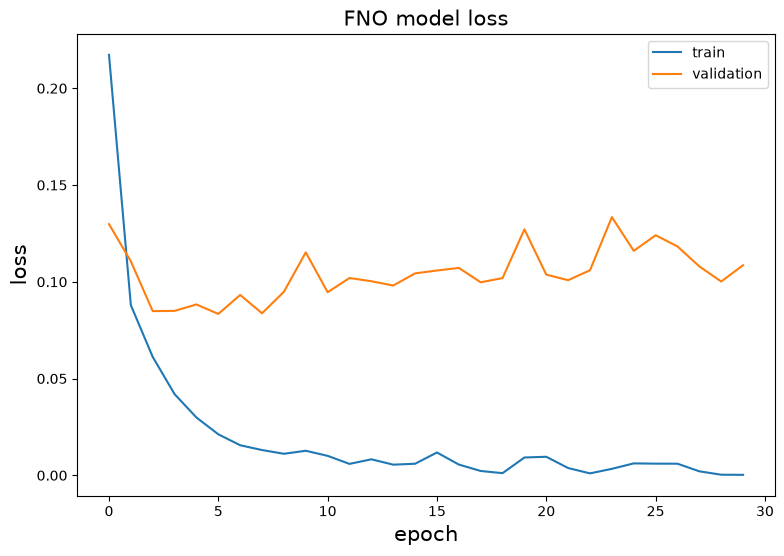

In [14]:
# Loss
plt.figure(figsize = (9, 6))
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.title('FNO model loss', fontsize = 15)
plt.ylabel('loss', fontsize = 15)
plt.xlabel('epoch', fontsize = 15)
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

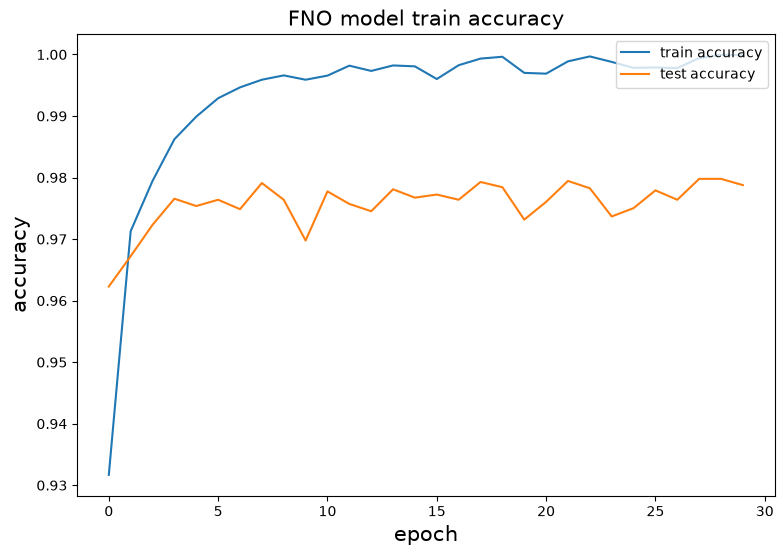

In [15]:
# Accuracy
plt.figure(figsize = (9, 6))
plt.plot(history['accuracy'])
plt.plot(history['val_accuracy'])
plt.title('FNO model train accuracy', fontsize = 15)
plt.xlabel('epoch', fontsize = 15)
plt.ylabel('accuracy', fontsize = 15)
plt.legend(['train accuracy', 'test accuracy'], loc = 'upper right')
plt.show()

---
# Evaluate the Testing Process (Loss and Accuracy)

In [16]:
test_loss, test_accuracy = evaluate(params, test_images, test_labels, BATCH_SIZE)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test loss: 0.1188
Test accuracy: 0.9790


---
# Visualizing Predictions

In [17]:
@jax.jit
def predict_step(params: dict[str, Any], images: jax.Array) -> jax.Array:
    return jax.nn.softmax(forward(params, images), axis=-1)


def predict(params: dict[str, Any], images: np.ndarray, batch_size: int) -> np.ndarray:
    predictions = []
    dummy_labels = np.zeros((images.shape[0],), dtype=np.int32)
    for batch_images, _ in batches(images, dummy_labels, batch_size):
        batch_predictions = predict_step(params, jnp.asarray(batch_images))
        predictions.append(np.asarray(batch_predictions))
    return np.concatenate(predictions, axis=0)


predictions = predict(params, test_images, BATCH_SIZE)

In [18]:
# Helper functions to plot images 
def plot_image(i, predictions_array, true_label, img):
  predictions_array, true_label, img = predictions_array, true_label[i], img[i]
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])

  plt.imshow(np.squeeze(img), cmap=plt.cm.binary)

  predicted_label = np.argmax(predictions_array)
  if predicted_label == true_label:
    color = 'blue'
  else:
    color = 'red'

  plt.xlabel("{} {:2.0f}% ({})".format(classess[predicted_label],
                                100*np.max(predictions_array),
                                classess[true_label]),
                                color=color)


def plot_value_array(i, predictions_array, true_label):
  predictions_array, true_label = predictions_array, true_label[i]
  plt.grid(False)
  plt.xticks(range(10))
  plt.yticks([])
  thisplot = plt.bar(range(10), predictions_array, color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(predictions_array)

  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')

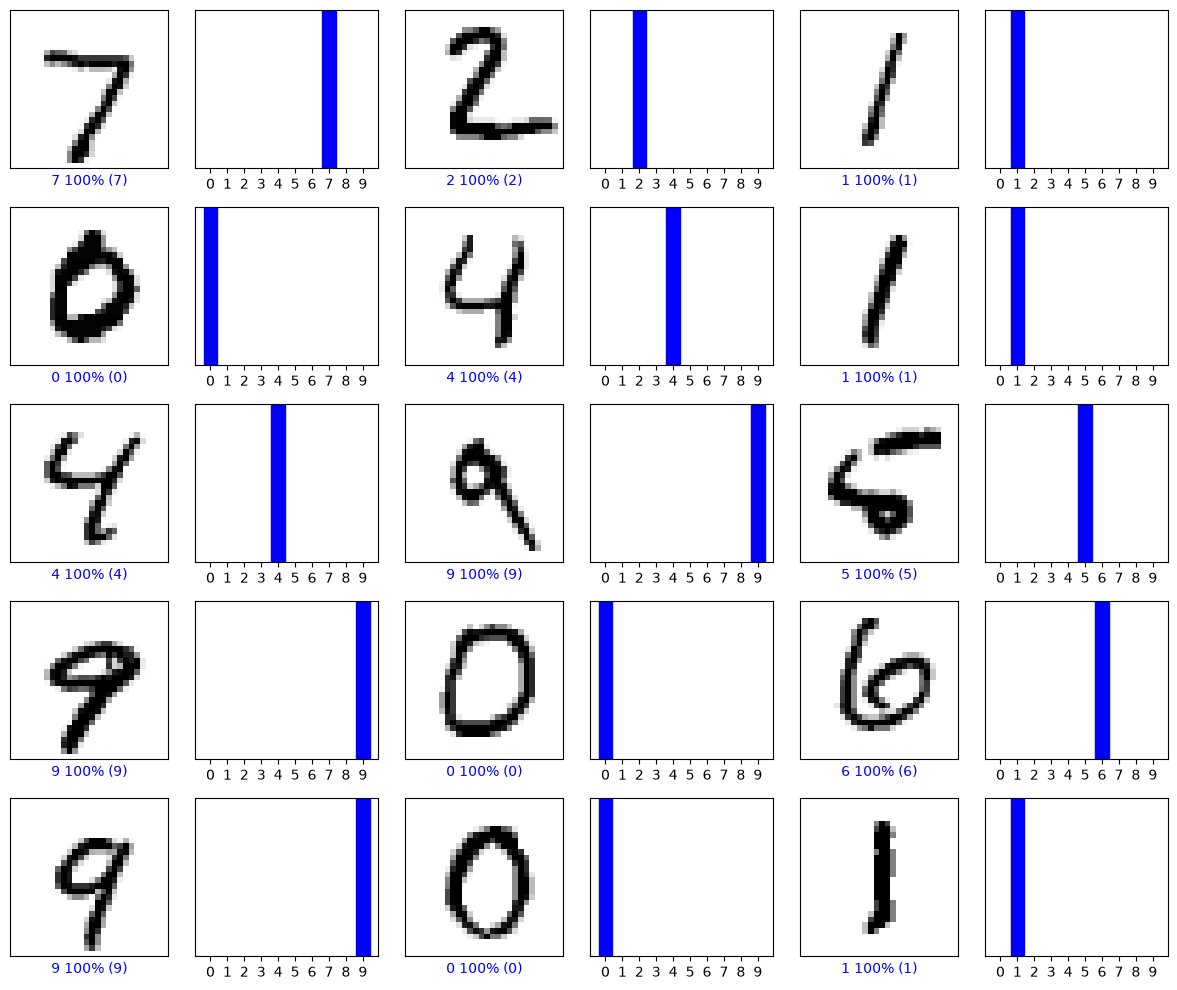

In [19]:
# Plot the first X test images, their predicted labels, and the true labels.
# Color correct predictions in blue and incorrect predictions in red.
num_rows = 5
num_cols = 3
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_image(i, predictions[i], test_labels, test_images)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_value_array(i, predictions[i], test_labels)
plt.tight_layout()
plt.show()

---

**Citations**

```
@misc{li2020fourier,
      title={Fourier Neural Operator for Parametric Partial Differential Equations},
      author={Zongyi Li and Nikola Kovachki and Kamyar Azizzadenesheli and Burigede Liu and Kaushik Bhattacharya and Andrew Stuart and Anima Anandkumar},
      year={2020},
      eprint={2010.08895},
      archivePrefix={arXiv},
      primaryClass={cs.LG}
}
```

[Author's github site](https://github.com/KozakHou)

[Zongyi Li's github site](https://github.com/zongyi-li/fourier_neural_operator)